In [ ]:
# This code block will create a 'Choose Files' button below. Press the button...
# and select the 'equipment_anomaly_data.csv' file from Kaggle. It should...
# display if the upload was successful

import matplotlib.pyplot as plt
import os
import shutil
import pandas as pd
from google.colab import files


print("Click the button below to select and upload your 'equipment_anomaly_data.csv' file:")
uploaded = files.upload()

filename = "equipment_anomaly_data.csv"
if os.path.exists(filename) and os.path.isfile(filename):
    # Load the CSV file into a pandas DataFrame
    data = pd.read_csv(filename)
    print("\nSuccess! The file has been uploaded and loaded successfully. Here are the first 5 rows:")
    display(data.head())
else:
    print(f"\nError: Please make sure the uploaded file is exactly named '{filename}'")

Click the button below to select and upload your 'equipment_anomaly_data.csv' file:


Saving equipment_anomaly_data.csv to equipment_anomaly_data.csv

Success! The file has been uploaded and loaded successfully. Here are the first 5 rows:


,temperature,pressure,vibration,humidity,equipment,location,faulty
0,58.180180,25.029278,0.606516,45.694907,Turbine,Atlanta,0.0
1,75.740712,22.954018,2.338095,41.867407,Compressor,Chicago,0.0
2,71.358594,27.276830,1.389198,58.954409,Turbine,San Francisco,0.0
3,71.616985,32.242921,1.770690,40.565138,Pump,Atlanta,0.0
4,66.506832,45.197471,0.345398,43.253795,Pump,New York,0.0


In [ ]:
# prints the data size of the csv file
print(f"The '{filename}' dataset has {data.shape} rows and columns")

The 'equipment_anomaly_data.csv' dataset has (7672, 7) rows and columns


In [ ]:
# prints the data type and amount of the csv file
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7672 entries, 0 to 7671
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temperature  7672 non-null   float64
 1   pressure     7672 non-null   float64
 2   vibration    7672 non-null   float64
 3   humidity     7672 non-null   float64
 4   equipment    7672 non-null   object 
 5   location     7672 non-null   object 
 6   faulty       7672 non-null   float64
dtypes: float64(5), object(2)
memory usage: 419.7+ KB


From the data.info() line we can see that there is no missing values and all all our data is numerical aside from the equipment and location

In [ ]:
# prints the summarized statistical data
data.describe()

,temperature,pressure,vibration,humidity,faulty
count,7672.000000,7672.000000,7672.000000,7672.000000,7672.000000
mean,70.922478,35.738048,1.611809,50.016574,0.099974
std,16.200059,10.381593,0.728560,11.841479,0.299985
min,10.269385,3.620798,-0.428188,10.215077,0.000000
25%,62.777057,29.485682,1.170906,42.612817,0.000000
50%,70.156900,35.227544,1.533113,50.024744,0.000000
75%,77.568387,41.159913,1.924700,57.340513,0.000000
max,149.690420,79.887734,4.990537,89.984718,1.000000


The summarised statistical data doesn't show any anomalies. The counts are all the same and the max values seem reasonable relative to their means.

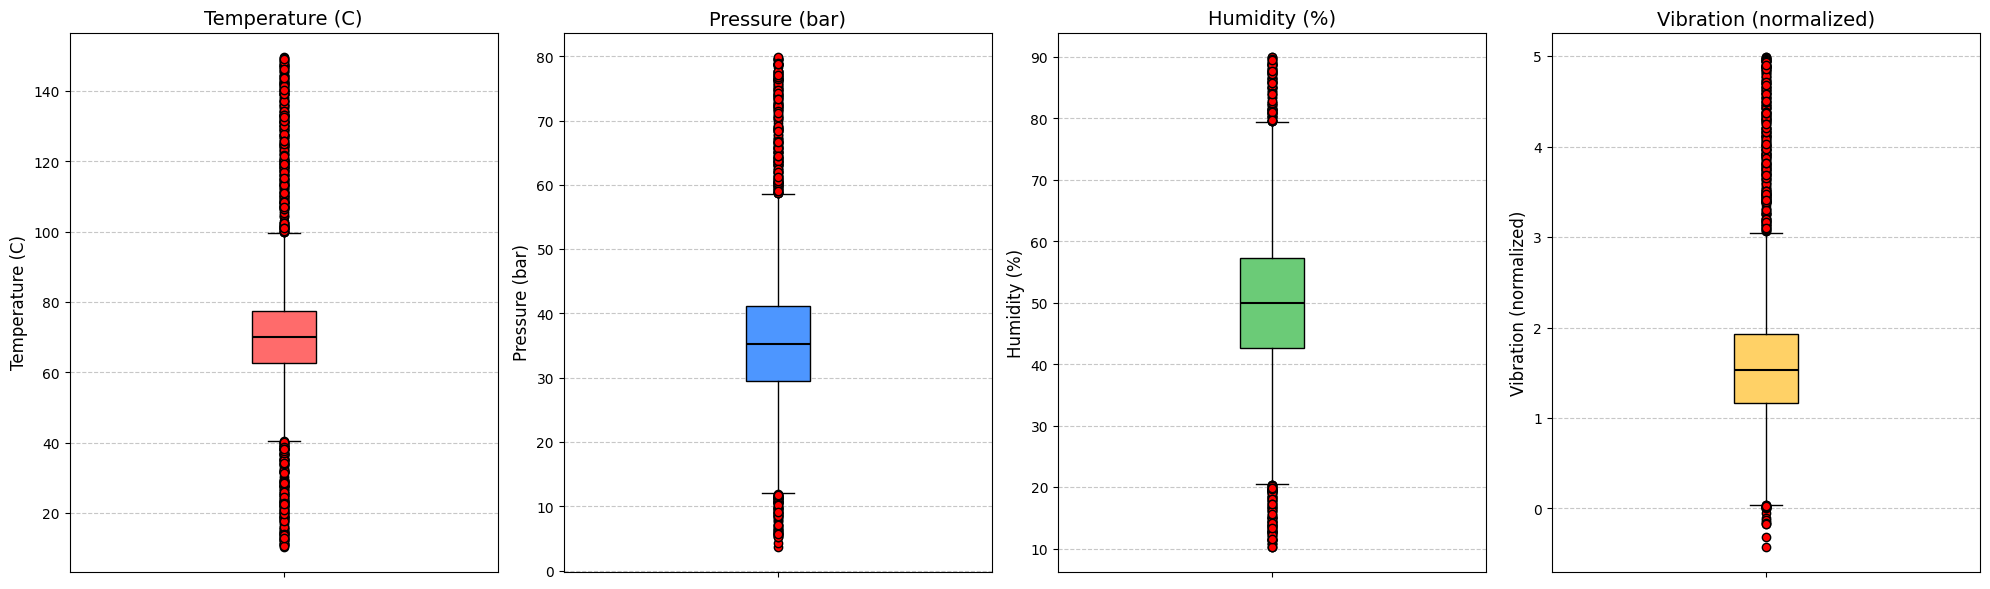

In [ ]:
# This block generates boxplots for each feature to more easily visualize potential outliers

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

features = ["temperature", "pressure", "humidity", "vibration"]
colors = ["#FF6B6B", "#4D96FF", "#6BCB77", "#FFD166"]

units = {
    "temperature": "(C)",
    "pressure": "(bar)",
    "humidity": "(%)",
    "vibration": "(normalized)"
}

for idx, col in enumerate(features):
    clean_data = data[col].dropna()

    flier_props = dict(marker='o', markerfacecolor='red', markersize=6, markeredgecolor='black', linestyle='none')
    box_props = dict(facecolor=colors[idx], color='black')
    median_props = dict(color='black', linewidth=1.5)

    axes[idx].boxplot(clean_data, patch_artist=True,
                      flierprops=flier_props,
                      boxprops=box_props,
                      medianprops=median_props)

    axes[idx].set_title(f'{col.capitalize()} {units[col]}', fontsize=14)
    axes[idx].set_ylabel(f"{col.capitalize()} {units[col]}", fontsize=12)
    axes[idx].set_xticklabels([])
    axes[idx].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Although there appear to be several outliers, the outliers are still within a reasonable measurement range which suggests that they are not incorrect measurements.

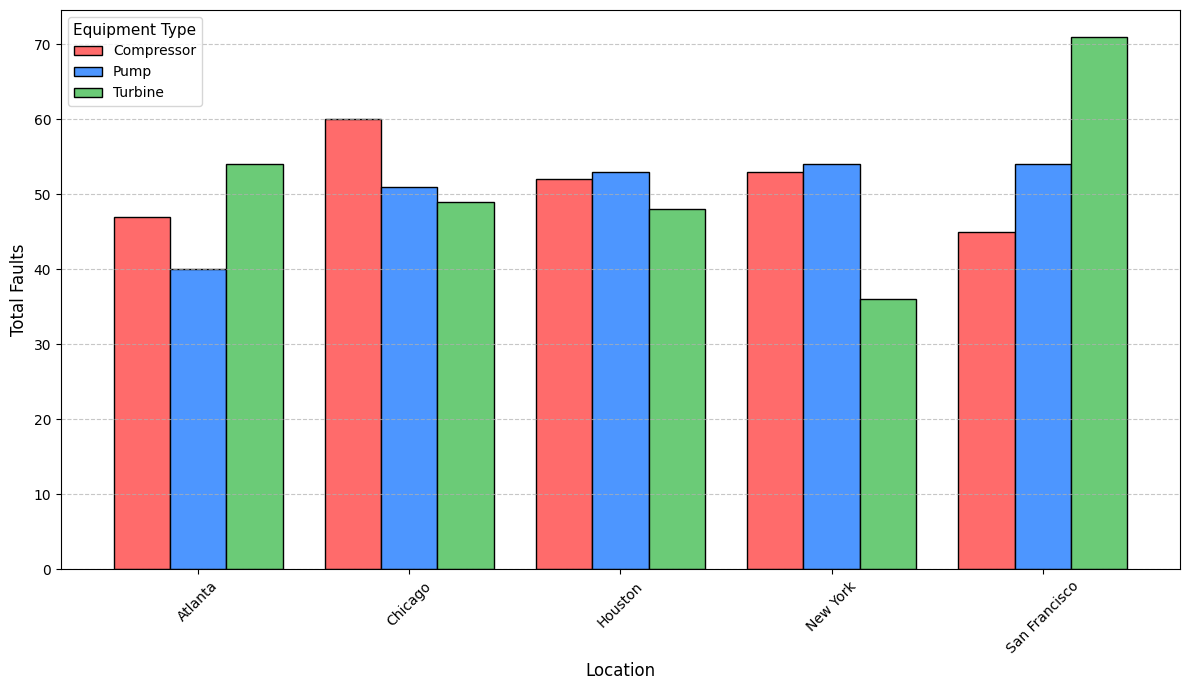

In [ ]:
# This block creates a bar chart that shows the number of faults for every type...
# of equipment based on location. This is to visualize potential data imbalances...
# and which locations need to pay more attention to maintenance

faults_breakdown = data.groupby(['location', 'equipment'])['faulty'].sum().unstack(fill_value=0)

equipment_colors = ['#FF6B6B', '#4D96FF', '#6BCB77', '#FFD166']

ax = faults_breakdown.plot(kind='bar', figsize=(12, 7), color=equipment_colors, edgecolor='black', width=0.8)

plt.xlabel('Location', fontsize=12)
plt.ylabel('Total Faults', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Equipment Type', fontsize=10, title_fontsize=11)

plt.tight_layout()
plt.show()

From the graph you can see how each location has a different number of faults for every type of location. This is a good way to visualize which locations need to pay more attention to the maintenance of their equipment

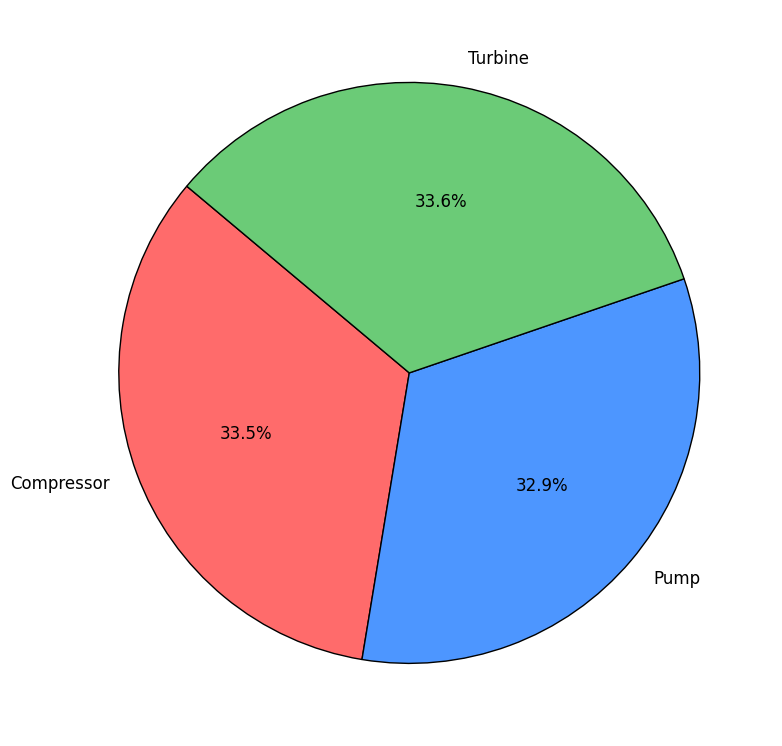

In [ ]:
# This code block creates a pie chart that shows how the data is distributed by...
# equipment type

equipment_failures = data.groupby('equipment')['faulty'].sum()

pie_colors = ['#FF6B6B', '#4D96FF', '#6BCB77']

plt.figure(figsize=(8, 8))
plt.pie(
    equipment_failures,
    labels=equipment_failures.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=pie_colors,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1, 'antialiased': True},
    textprops={'fontsize': 12}
)

plt.tight_layout()
plt.show()

In the pie chart we can see that the number of break downs of each equipment is relatively equal.

This figure shows that 90% of our data is not faulty.

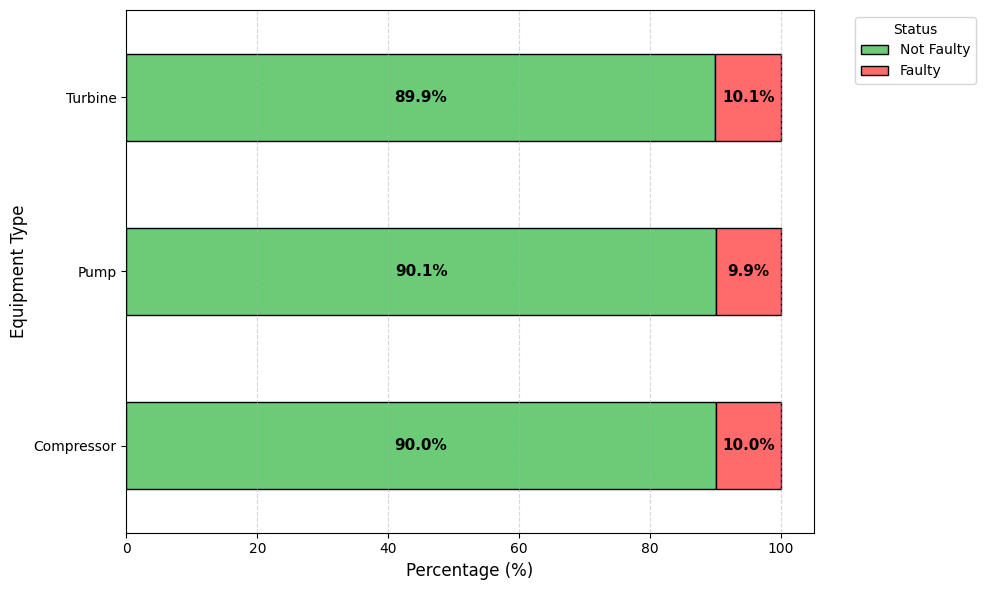

In [ ]:
# This code block shows how much of the data is faulty vs not faulty

equipment_status = data.groupby(['equipment', 'faulty']).size().unstack(fill_value=0)

equipment_status.columns = ['Not Faulty', 'Faulty']

equipment_status_pct = equipment_status.div(equipment_status.sum(axis=1), axis=0) * 100

status_colors = ['#6BCB77', '#FF6B6B']

ax = equipment_status_pct.plot(kind='barh', figsize=(10, 6), stacked=True, color=status_colors, edgecolor='black')

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{width:.1f}%',
                    (p.get_x() + width / 2,
                     p.get_y() + p.get_height() / 2),
                    ha='center', va='center',
                    color='black', weight='bold', fontsize=11)

plt.xlabel('Percentage (%)', fontsize=12)
plt.ylabel('Equipment Type', fontsize=12)
plt.legend(title='Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Here it is clear to see that our data is imbalanced; There is more not faulty data points than faulty data points. This means we have to be careful when we train the model to account for that using balanaced accuracy.

Logistic Regression Model

In [ ]:
# This code block makes required imports

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    log_loss,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

In [ ]:
# This code block assigns a number to each equipment type and then creates...
# a baseline logistic regression model using all features. It then evaluates...
# the effectiveness of the model

equipment_map = {"compressor": 1, "pump": 2, "turbine": 3}
data["equipment_mapped"] = data["equipment"].str.lower().map(equipment_map)

X = data[
    ["temperature", "pressure", "humidity", "equipment_mapped"]
]
y = data["faulty"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=100, solver='lbfgs')

model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

y_prob = model.predict_proba(X_test)

y_pred = model.predict(X_test)

print("\n")

ce = log_loss(y_test, y_prob)
accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print("Number of iterations completed:", model.n_iter_)

print("\nCross-Entropy Loss:", ce)
print("Accuracy:", accuracy)
print("Balanced Accuracy:", balanced_acc)
print("Confusion Matrix:")
print(cm)

Intercept: [-6.06575616]
Coefficients: [[0.02463794 0.04866201 0.00384444 0.01075101]]


Number of iterations completed: [46]

Cross-Entropy Loss: 0.27800611808874953
Accuracy: 0.9114006514657981
Balanced Accuracy: 0.5555555555555556
Confusion Matrix:
[[1382    0]
 [ 136   17]]


Although the accuracy score is quite high, the ballanced accuracy and the confusion matrix shows a more accurate picture. The balanced accuracy is quite low which is a good representation of our data imbalance. The confusion matrix also shows that all of our incorrect predictions were false negatives (predicted not faulty when it is faulty. This is not acceptable. We want to reduce the amount of false negatives as much as possible because it is a lot riskier for equipment and people than a false positive where you potentially just need to check that its ok.

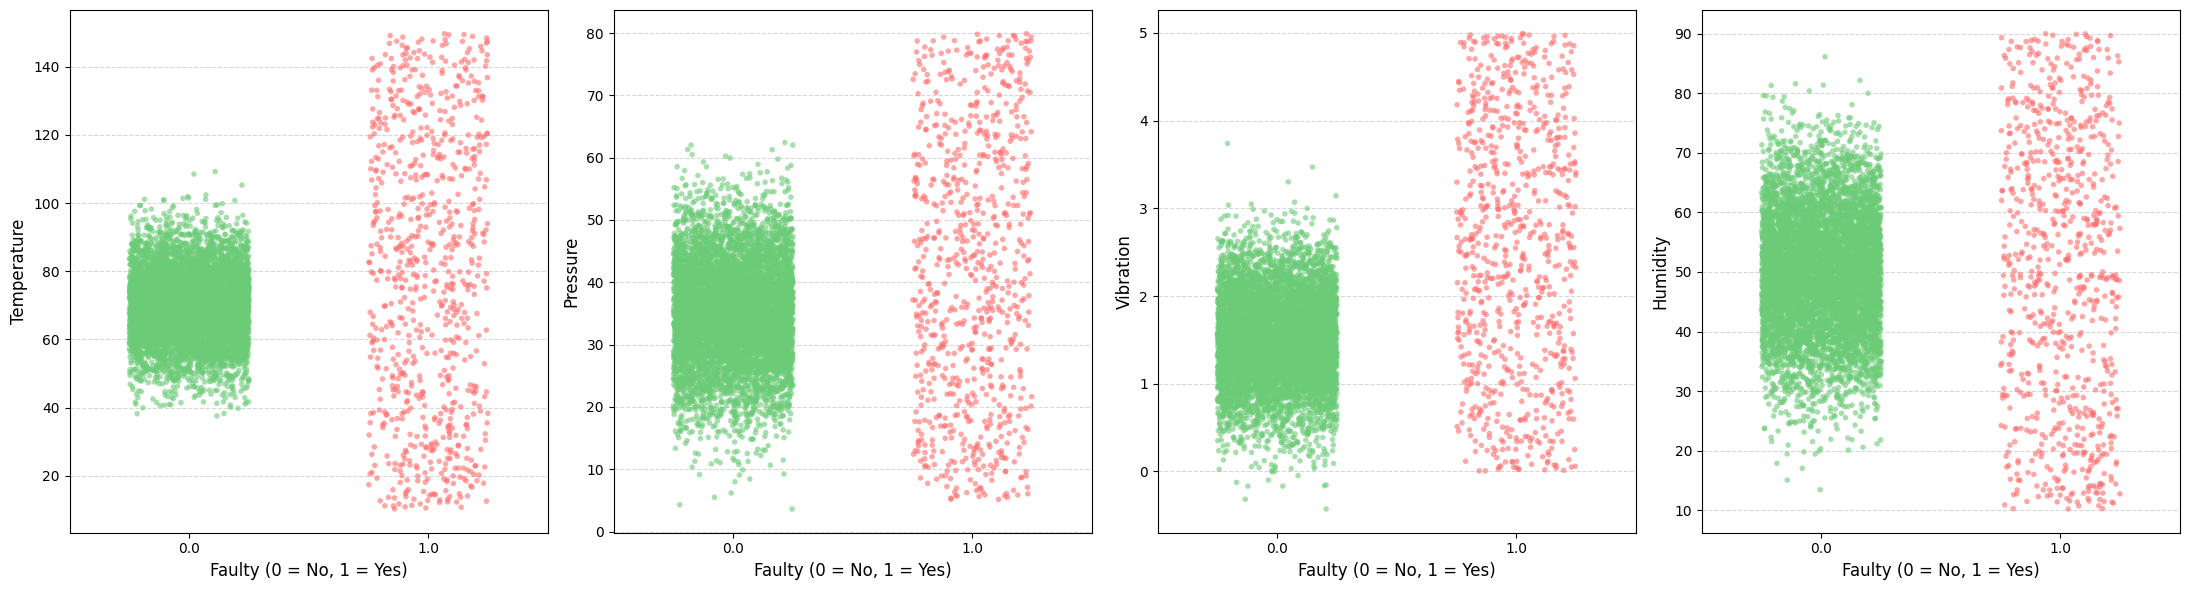

In [ ]:
# This code block plots each feature vs faulty/not faulty. It...
# also has jitter so that it is easier to see correlations in the data

import matplotlib.pyplot as plt
import seaborn as sns

features = ["temperature", "pressure", "vibration", "humidity"]

fig, axes = plt.subplots(1, 4, figsize=(22, 6))

for idx, col in enumerate(features):
    sns.stripplot(
        ax=axes[idx],
        x="faulty",
        y=col,
        data=data,
        palette=["#6BCB77", "#FF6B6B"],
        hue="faulty",
        jitter=0.25,
        size=4,
        alpha=0.6,
        legend=False
    )

    axes[idx].set_xlabel("Faulty (0 = No, 1 = Yes)", fontsize=12)
    axes[idx].set_ylabel(col.capitalize(), fontsize=12)
    axes[idx].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

The pressure, temperature, and vibration all show that higher values generally correlate to faulty equipment. The humidity however, is spread out more evenly which could suggest a weaker correlation.

In [ ]:
# This code block creates a model with the features scaled

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaled_model = LogisticRegression(max_iter=100, solver='lbfgs')
scaled_model.fit(X_train_scaled, y_train)

y_prob_scaled = scaled_model.predict_proba(X_test_scaled)
y_pred_scaled = scaled_model.predict(X_test_scaled)

ce_scaled = log_loss(y_test, y_prob_scaled)
accuracy_scaled = accuracy_score(y_test, y_pred_scaled)
balanced_acc_scaled = balanced_accuracy_score(y_test, y_pred_scaled)
cm_scaled = confusion_matrix(y_test, y_pred_scaled)

print("--- Scaled Model Results ---")
print("Intercept:", scaled_model.intercept_)
print("Coefficients:", scaled_model.coef_)
print("Number of iterations completed:", scaled_model.n_iter_)
print("\nCross-Entropy Loss:", ce_scaled)
print("Accuracy:", accuracy_scaled)
print("Balanced Accuracy:", balanced_acc_scaled)
print("Confusion Matrix:")
print(cm_scaled)

--- Scaled Model Results ---
Intercept: [-5.31920133]
Coefficients: [[3.10624919 3.46413093 0.31111757 0.02434788]]
Number of iterations completed: [17]

Cross-Entropy Loss: 0.2799166039653791
Accuracy: 0.9100977198697069
Balanced Accuracy: 0.5490196078431373
Confusion Matrix:
[[1382    0]
 [ 138   15]]


The balanced accuracy score surprisingly went down after scaling the data. Unscaled data will be used from now on going forward.

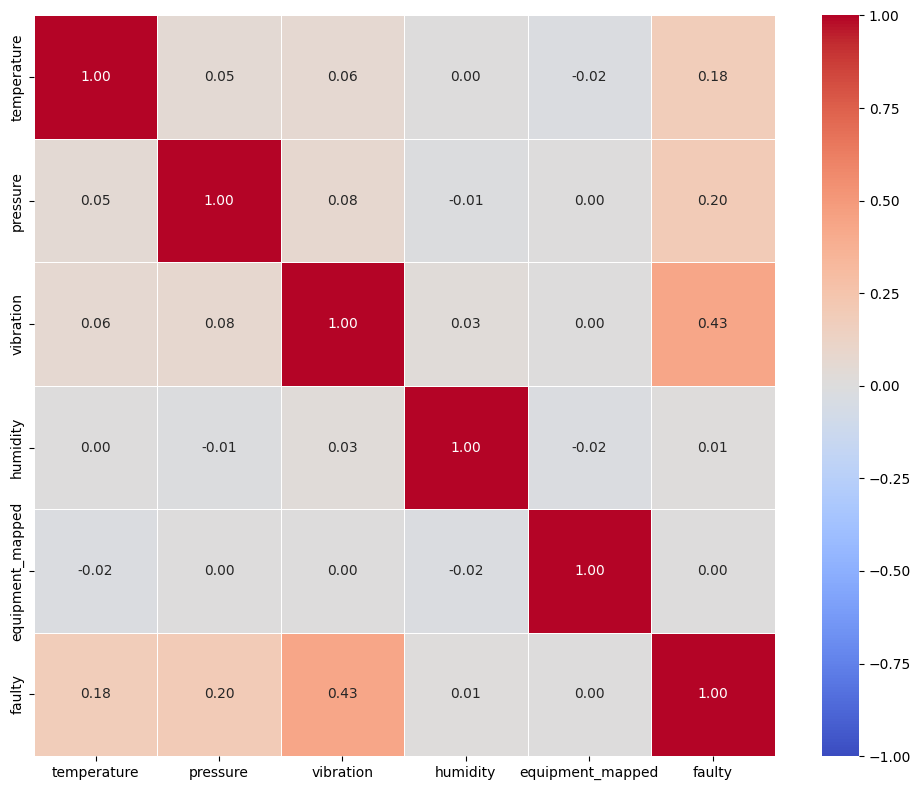

In [ ]:
# This code block creates a pearson correlation heat map

import seaborn as sns
import matplotlib.pyplot as plt

numerical_cols = ["temperature", "pressure", "vibration", "humidity", "equipment_mapped", "faulty"]
correlation_matrix = data[numerical_cols].corr(method="pearson")

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    square=True
)


plt.tight_layout()
plt.show()

The correlation heatmap above shows that the vibration data has the highest correlation with the faulty output data. Temperature and pressure have moderate correlation to the faulty data and humidity and equipment type has almost no correlation to the faulty output data. The humidity data will not be used to train the model anymore.

In [ ]:
# This code block creates a model without the humidity feature

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, accuracy_score, balanced_accuracy_score, confusion_matrix

X_no_humidity = data[["temperature", "pressure", "vibration", "equipment_mapped"]]
y_no_humidity = data["faulty"]

X_train_nh, X_test_nh, y_train_nh, y_test_nh = train_test_split(
    X_no_humidity,
    y_no_humidity,
    test_size=0.20,
    random_state=42,
    stratify=y_no_humidity
)

no_humidity_model = LogisticRegression(max_iter=100, solver='lbfgs')
no_humidity_model.fit(X_train_nh, y_train_nh)

y_prob_nh = no_humidity_model.predict_proba(X_test_nh)
y_pred_nh = no_humidity_model.predict(X_test_nh)

ce_nh = log_loss(y_test_nh, y_prob_nh)
accuracy_nh = accuracy_score(y_test_nh, y_pred_nh)
balanced_acc_nh = balanced_accuracy_score(y_test_nh, y_pred_nh)
cm_nh = confusion_matrix(y_test_nh, y_pred_nh)

print("--- Model Results (Excluding Humidity) ---")
print("Intercept:", no_humidity_model.intercept_)
print("Coefficients:", no_humidity_model.coef_)
print("Number of iterations completed:", no_humidity_model.n_iter_)
print("\nCross-Entropy Loss:", ce_nh)
print("Accuracy:", accuracy_nh)
print("Balanced Accuracy:", balanced_acc_nh)
print("Confusion Matrix:")
print(cm_nh)

--- Model Results (Excluding Humidity) ---
Intercept: [-8.37033376]
Coefficients: [[ 0.02169939  0.04382821  1.56566129 -0.00570215]]
Number of iterations completed: [61]

Cross-Entropy Loss: 0.22480760768993388
Accuracy: 0.9420195439739414
Balanced Accuracy: 0.7120565061528712
Confusion Matrix:
[[1381    1]
 [  88   65]]


The model performance improved drastically from removing the humidity feature. THe balanced accuracy increase by ~16%. Interesting that the number of iterations increased so much. Although the iterations to train the model increased, there is also 1 less parameter now.

In [ ]:
# This code block uses the sequential feature selector to create a model...
# based on the most effective features selected in sequence

from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, accuracy_score, balanced_accuracy_score, confusion_matrix
import pandas as pd

X_all = data[["temperature", "pressure", "vibration", "humidity", "equipment_mapped"]]
y_all = data["faulty"]

X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all
)

base_estimator = LogisticRegression(max_iter=100, solver='lbfgs')

sfs = SequentialFeatureSelector(
    base_estimator,
    n_features_to_select=3,
    direction='forward',
    scoring='balanced_accuracy',
    cv=5
)

sfs.fit(X_train_all, y_train_all)

selected_features = X_all.columns[sfs.get_support()].tolist()
print("Selected Features via SFS:", selected_features)

X_train_sfs = sfs.transform(X_train_all)
X_test_sfs = sfs.transform(X_test_all)

sfs_model = LogisticRegression(max_iter=100, solver='lbfgs')
sfs_model.fit(X_train_sfs, y_train_all)

y_prob_sfs = sfs_model.predict_proba(X_test_sfs)
y_pred_sfs = sfs_model.predict(X_test_sfs)

ce_sfs = log_loss(y_test_all, y_prob_sfs)
accuracy_sfs = accuracy_score(y_test_all, y_pred_sfs)
balanced_acc_sfs = balanced_accuracy_score(y_test_all, y_pred_sfs)
cm_sfs = confusion_matrix(y_test_all, y_pred_sfs)

print("\n--- SFS Model Results ---")
print("Intercept:", sfs_model.intercept_)
print("Coefficients:", sfs_model.coef_)
print("Number of iterations completed:", sfs_model.n_iter_)
print("\nCross-Entropy Loss:", ce_sfs)
print("Accuracy:", accuracy_sfs)
print("Balanced Accuracy:", balanced_acc_sfs)
print("Confusion Matrix:")
print(cm_sfs)

Selected Features via SFS: ['temperature', 'pressure', 'vibration']

--- SFS Model Results ---
Intercept: [-8.3814407]
Coefficients: [[0.02170163 0.04381777 1.5656288 ]]
Number of iterations completed: [37]

Cross-Entropy Loss: 0.2248126464673683
Accuracy: 0.9413680781758957
Balanced Accuracy: 0.708788532296662
Confusion Matrix:
[[1381    1]
 [  89   64]]


The sequential feature selector decided to drop the equipment type and humidity which confirms our earlier observation that those features don't correlate well with the output. The performance of the model stayed the same with far less iterations required and one less parameter in the model.  

In [ ]:
!pip install -q mlxtend

In [ ]:
# This code block creates a model using the exhaustive feature selector which...
# selects the best features based on all combinations of features

from mlxtend.feature_selection import ExhaustiveFeatureSelector as EFS
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, accuracy_score, balanced_accuracy_score, confusion_matrix
import pandas as pd

X_all = data[["temperature", "pressure", "vibration", "humidity", "equipment_mapped"]]
y_all = data["faulty"]

X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all
)

lr = LogisticRegression(max_iter=100, solver='lbfgs')

efs = EFS(
    lr,
    min_features=1,
    max_features=4,
    scoring='balanced_accuracy',
    print_progress=False,
    cv=5
)

efs.fit(X_train_all, y_train_all)

selected_indices = list(efs.best_idx_)
selected_features_efs = [X_all.columns[i] for i in selected_indices]
print("Selected Features via EFS:", selected_features_efs)

X_train_efs = X_train_all[selected_features_efs]
X_test_efs = X_test_all[selected_features_efs]

efs_model = LogisticRegression(max_iter=100, solver='lbfgs')
efs_model.fit(X_train_efs, y_train_all)

y_prob_efs = efs_model.predict_proba(X_test_efs)
y_pred_efs = efs_model.predict(X_test_efs)

ce_efs = log_loss(y_test_all, y_prob_efs)
accuracy_efs = accuracy_score(y_test_all, y_pred_efs)
balanced_acc_efs = balanced_accuracy_score(y_test_all, y_pred_efs)
cm_efs = confusion_matrix(y_test_all, y_pred_efs)

print("\n--- EFS Model Results ---")
print("Intercept:", efs_model.intercept_)
print("Coefficients:", efs_model.coef_)
print("Number of iterations completed:", efs_model.n_iter_)
print("\nCross-Entropy Loss:", ce_efs)
print("Accuracy:", accuracy_efs)
print("Balanced Accuracy:", balanced_acc_efs)
print("Confusion Matrix:")
print(cm_efs)

Selected Features via EFS: ['temperature', 'pressure', 'vibration']

--- EFS Model Results ---
Intercept: [-8.3814407]
Coefficients: [[0.02170163 0.04381777 1.5656288 ]]
Number of iterations completed: [37]

Cross-Entropy Loss: 0.2248126464673683
Accuracy: 0.9413680781758957
Balanced Accuracy: 0.708788532296662
Confusion Matrix:
[[1381    1]
 [  89   64]]


Even with an exhaustive search, the selected features remain the same. The performance stays the exact same with the same number of iterations. From an engineering perspective however, the type of equipment could potentially affect the temperature, vibration, or pressure readings. So I hesitate to completely eliminate the equipment type. Maybe the data can be split up into the equipment types and train each model seperately.

In [ ]:
# This code block splits the data set based on equipment type, creates a model...
# for each equipment type, evaluates each model, and then combines the results

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, accuracy_score, balanced_accuracy_score, confusion_matrix
import pandas as pd
import numpy as np

features_list = ["temperature", "pressure", "vibration"]
target = "faulty"

train_data, test_data = train_test_split(
    data,
    test_size=0.20,
    random_state=42,
    stratify=data[target]
)

equipment_types = ["compressor", "pump", "turbine"]
models = {}
y_test_list = []
y_prob_list = []
y_pred_list = []

print("--- Training Individual Equipment Models (Excluding Humidity) ---")
for eq in equipment_types:
    train_eq = train_data[train_data["equipment"].str.lower() == eq]
    test_eq = test_data[test_data["equipment"].str.lower() == eq]

    X_train_eq = train_eq[features_list]
    y_train_eq = train_eq[target]
    X_test_eq = test_eq[features_list]
    y_test_eq = test_eq[target]

    eq_model = LogisticRegression(max_iter=100, solver='lbfgs')
    eq_model.fit(X_train_eq, y_train_eq)
    models[eq] = eq_model

    probs = eq_model.predict_proba(X_test_eq)
    preds = eq_model.predict(X_test_eq)

    y_test_list.append(y_test_eq)
    y_prob_list.append(probs)
    y_pred_list.append(preds)

    eq_ce = log_loss(y_test_eq, probs)
    eq_acc = accuracy_score(y_test_eq, preds)
    eq_bal_acc = balanced_accuracy_score(y_test_eq, preds)
    print(f"\n[{eq.upper()} Model Properties]")
    print(f"Intercept: {eq_model.intercept_}")
    print(f"Coefficients: {eq_model.coef_}")
    print(f"Iterations completed: {eq_model.n_iter_}")
    print(f"Cross-Entropy Loss: {eq_ce:.5f}")
    print(f"Accuracy: {eq_acc * 100:.2f}%")
    print(f"Balanced Accuracy: {eq_bal_acc * 100:.2f}%")

y_test_combined = pd.concat(y_test_list)
y_prob_combined = np.concatenate(y_prob_list, axis=0)
y_pred_combined = np.concatenate(y_pred_list, axis=0)

ce_combined = log_loss(y_test_combined, y_prob_combined)
accuracy_combined = accuracy_score(y_test_combined, y_pred_combined)
balanced_acc_combined = balanced_accuracy_score(y_test_combined, y_pred_combined)
cm_combined = confusion_matrix(y_test_combined, y_pred_combined)

print("\n===============================================")
print("--- COMBINED MULTI-MODEL SYSTEM RESULTS ---")
print("===============================================")
print("Cross-Entropy Loss:", ce_combined)
print("Accuracy:", accuracy_combined)
print("Balanced Accuracy:", balanced_acc_combined)
print("Confusion Matrix:")
print(cm_combined)


--- Training Individual Equipment Models (Excluding Humidity) ---

[COMPRESSOR Model Properties]
Intercept: [-8.16722859]
Coefficients: [[0.02340942 0.03858946 1.48575861]]
Iterations completed: [36]
Cross-Entropy Loss: 0.23756
Accuracy: 92.80%
Balanced Accuracy: 66.26%

[PUMP Model Properties]
Intercept: [-7.93915279]
Coefficients: [[0.0152773  0.03961334 1.68018114]]
Iterations completed: [49]
Cross-Entropy Loss: 0.18389
Accuracy: 95.49%
Balanced Accuracy: 75.56%

[TURBINE Model Properties]
Intercept: [-9.01243999]
Coefficients: [[0.02620794 0.05331661 1.51583298]]
Iterations completed: [42]
Cross-Entropy Loss: 0.25160
Accuracy: 94.22%
Balanced Accuracy: 71.70%

--- COMBINED MULTI-MODEL SYSTEM RESULTS ---
Cross-Entropy Loss: 0.2252437853576779
Accuracy: 0.9413680781758957
Balanced Accuracy: 0.708788532296662
Confusion Matrix:
[[1381    1]
 [  89   64]]


Seperating the data by equipment type did not improve the performance of the model. To me this shows the limitations of using a simulated/generated data set. I think if this dataset was from industry, the readings correlating to failure of each equipment type would likely be different, but I guess it could be the same type of bearings that are failing in each equipment. This does show that pumps are easier to predict than the other types of equipment.

In [ ]:
# This code block creates a model using balanced weights

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, accuracy_score, balanced_accuracy_score, confusion_matrix
import pandas as pd

features_list = ["temperature", "pressure", "vibration"]
target = "faulty"

X_bal = data[features_list]
y_bal = data[target]

X_train_bal, X_test_bal, y_train_bal, y_test_bal = train_test_split(
    X_bal,
    y_bal,
    test_size=0.20,
    random_state=42,
    stratify=y_bal
)

balanced_weight_model = LogisticRegression(max_iter=100, solver='lbfgs', class_weight='balanced')
balanced_weight_model.fit(X_train_bal, y_train_bal)

y_prob_bal = balanced_weight_model.predict_proba(X_test_bal)
y_pred_bal = balanced_weight_model.predict(X_test_bal)

ce_bal = log_loss(y_test_bal, y_prob_bal)
accuracy_bal = accuracy_score(y_test_bal, y_pred_bal)
balanced_acc_bal = balanced_accuracy_score(y_test_bal, y_pred_bal)
cm_bal = confusion_matrix(y_test_bal, y_pred_bal)

print("--- Model Results (Balanced Weights) ---")
print("Intercept:", balanced_weight_model.intercept_)
print("Coefficients:", balanced_weight_model.coef_)
print("Number of iterations completed:", balanced_weight_model.n_iter_)
print("\nCross-Entropy Loss:", ce_bal)
print("Accuracy:", accuracy_bal)
print("Balanced Accuracy:", balanced_acc_bal)
print("Confusion Matrix:")
print(cm_bal)

--- Model Results (Balanced Weights) ---
Intercept: [-3.89385211]
Coefficients: [[0.01195888 0.02813981 1.00322615]]
Number of iterations completed: [31]

Cross-Entropy Loss: 0.4943933888260402
Accuracy: 0.826058631921824
Balanced Accuracy: 0.7551857211770381
Confusion Matrix:
[[1166  216]
 [  51  102]]


Making the weighting more balanced made the model more sensitive the faults. The increase in sensitivity to faults caused more false positives but less false negatives. This is highly preferred to prevent damage to equipment. This als means that the overall accuracy of the model decreased but the balanced accuracy increased.

In [ ]:
# This code block creates a model with custom weights

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, accuracy_score, balanced_accuracy_score, confusion_matrix

custom_weights = {0: 1, 1: 5}

custom_weight_model = LogisticRegression(max_iter=100, solver='lbfgs', class_weight=custom_weights)
custom_weight_model.fit(X_train_bal, y_train_bal)

y_prob_custom = custom_weight_model.predict_proba(X_test_bal)
y_pred_custom = custom_weight_model.predict(X_test_bal)

ce_custom = log_loss(y_test_bal, y_prob_custom)
accuracy_custom = accuracy_score(y_test_bal, y_pred_custom)
balanced_acc_custom = balanced_accuracy_score(y_test_bal, y_pred_custom)
cm_custom = confusion_matrix(y_test_bal, y_pred_custom)

print("--- Model Results (Custom Weights: {0: 1, 1: 5}) ---")
print("Intercept:", custom_weight_model.intercept_)
print("Coefficients:", custom_weight_model.coef_)
print("Number of iterations completed:", custom_weight_model.n_iter_)
print("\nCross-Entropy Loss:", ce_custom)
print("Accuracy:", accuracy_custom)
print("Balanced Accuracy:", balanced_acc_custom)
print("Confusion Matrix:")
print(cm_custom)

--- Model Results (Custom Weights: {0: 1, 1: 5}) ---
Intercept: [-5.06647928]
Coefficients: [[0.01435038 0.03230707 1.14695145]]
Number of iterations completed: [34]

Cross-Entropy Loss: 0.34917517008236426
Accuracy: 0.9368078175895765
Balanced Accuracy: 0.7847228133897071
Confusion Matrix:
[[1347   35]
 [  62   91]]


Changing the weighting during training to a custom weighting that punishes false positives more (5:1 weighting for catching faults) has increased the balanced accuracy by drastically reducing the false positives; however, the number of false negatives increased slightly

In [ ]:
# This code block lowers threshold the threshold of the last model

y_prob_positive = y_prob_custom[:, 1]

threshold = 0.4
y_pred_low_threshold = (y_prob_positive >= threshold).astype(int)

accuracy_low = accuracy_score(y_test_bal, y_pred_low_threshold)
balanced_acc_low = balanced_accuracy_score(y_test_bal, y_pred_low_threshold)
cm_low = confusion_matrix(y_test_bal, y_pred_low_threshold)

print(f"--- Model Results with Custom Weights and Lower Threshold ({threshold}) ---")
print("Cross-Entropy Loss (same as before):", ce_custom)
print("Accuracy:", accuracy_low)
print("Balanced Accuracy:", balanced_acc_low)
print("Confusion Matrix:")
print(cm_low)

--- Model Results with Custom Weights and Lower Threshold (0.4) ---
Cross-Entropy Loss (same as before): 0.34917517008236426
Accuracy: 0.8716612377850163
Balanced Accuracy: 0.7746989775167182
Confusion Matrix:
[[1238  144]
 [  53  100]]


By lowering the threshold to 0.4 (from 0.5) we were able to reduce the number of false negatives by 9 while only lowering the balanced accuracy by ~1%. The false positives increased dramatically however. The decision can now be made if the trade off of having much more false positives is worth having much less false negatives. To avoid faulty equipment being missed, I would say it is worth it.

In [ ]:
# This code block creates a random forest model with balanced weights

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss, accuracy_score, balanced_accuracy_score, confusion_matrix

rf_balanced_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_balanced_model.fit(X_train_bal, y_train_bal)

y_prob_rf = rf_balanced_model.predict_proba(X_test_bal)
y_pred_rf = rf_balanced_model.predict(X_test_bal)

ce_rf = log_loss(y_test_bal, y_prob_rf)
accuracy_rf = accuracy_score(y_test_bal, y_pred_rf)
balanced_acc_rf = balanced_accuracy_score(y_test_bal, y_pred_rf)
cm_rf = confusion_matrix(y_test_bal, y_pred_rf)

print("--- Random Forest Model Results (Balanced Weights) ---")
print("Cross-Entropy Loss:", ce_rf)
print("Accuracy:", accuracy_rf)
print("Balanced Accuracy:", balanced_acc_rf)
print("Confusion Matrix:")
print(cm_rf)

--- Random Forest Model Results (Balanced Weights) ---
Cross-Entropy Loss: 0.16749148654196377
Accuracy: 0.9817589576547231
Balanced Accuracy: 0.9230276288035716
Confusion Matrix:
[[1377    5]
 [  23  130]]


The random forest model is clearly superior over the logistal regression model because it is more effective at handling non-linear relationships

In [ ]:
# This random forest model uses all features including humidity and equipment type

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss, accuracy_score, balanced_accuracy_score, confusion_matrix

rf_all_features_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_all_features_model.fit(X_train_all, y_train_all)

y_prob_rf_all = rf_all_features_model.predict_proba(X_test_all)
y_pred_rf_all = rf_all_features_model.predict(X_test_all)

ce_rf_all = log_loss(y_test_all, y_prob_rf_all)
accuracy_rf_all = accuracy_score(y_test_all, y_pred_rf_all)
balanced_acc_rf_all = balanced_accuracy_score(y_test_all, y_pred_rf_all)
cm_rf_all = confusion_matrix(y_test_all, y_pred_rf_all)

print("--- Random Forest Model Results (All Features & Balanced Weights) ---")
print("Cross-Entropy Loss:", ce_rf_all)
print("Accuracy:", accuracy_rf_all)
print("Balanced Accuracy:", balanced_acc_rf_all)
print("Confusion Matrix:")
print(cm_rf_all)

--- Random Forest Model Results (All Features & Balanced Weights) ---
Cross-Entropy Loss: 0.11522166958119827
Accuracy: 0.9830618892508143
Balanced Accuracy: 0.92956357651599
Confusion Matrix:
[[1377    5]
 [  21  132]]


The random forest model is better able to pick up on subtle relationships from the humidity and equipment type data that the logistical regression model was unable to do which lead to a slight decrease in cross entropy error; however, at such a small decrease in error, it would be beneficial to further test/validate this model based on another dataset to ensure the model wasn't overtrained.

In [ ]:
# This code block lowers the threshold of the last model

y_prob_rf_positive = y_prob_rf_all[:, 1]

rf_threshold = 0.2
y_pred_rf_low = (y_prob_rf_positive >= rf_threshold).astype(int)

accuracy_rf_low = accuracy_score(y_test_all, y_pred_rf_low)
balanced_acc_rf_low = balanced_accuracy_score(y_test_all, y_pred_rf_low)
cm_rf_low = confusion_matrix(y_test_all, y_pred_rf_low)

print(f"--- Random Forest (All Features) with Threshold {rf_threshold} ---")
print("Accuracy:", accuracy_rf_low)
print("Balanced Accuracy:", balanced_acc_rf_low)
print("Confusion Matrix:")
print(cm_rf_low)

--- Random Forest (All Features) with Threshold 0.2 ---
Accuracy: 0.9771986970684039
Balanced Accuracy: 0.9669939369862754
Confusion Matrix:
[[1354   28]
 [   7  146]]


By decreasing the threshold to 0.2 (from 0.5) we were able to increase the balanced accuracy from 93% to 96.7%. We were also able to decrease the amount of false negatives from 21 to 7. Althought the false positives increased from 5 to 28, this is still much prefered over having too many false negatives.

In [ ]:
# This code block prints the performance of every model created so far

from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models_eval = {
    "1. Baseline Logistic Regression": (y_test, y_pred),
    "2. Scaled Logistic Regression": (y_test, y_pred_scaled),
    "3. Logistic Regression (No Humidity)": (y_test_nh, y_pred_nh),
    "4. SFS Logistic Regression (3 features)": (y_test_all, y_pred_sfs),
    "5. EFS Logistic Regression (3 features)": (y_test_all, y_pred_efs),
    "6. Combined Multi-Model (by Equipment)": (y_test_combined, y_pred_combined),
    "7. Logistic Regression (Balanced Weights)": (y_test_bal, y_pred_bal),
    "8. Logistic Regression (Custom Weights 1:5)": (y_test_bal, y_pred_custom),
    "9. Logistic Regression (Custom + Threshold 0.4)": (y_test_bal, y_pred_low_threshold),
    "10. Random Forest (Balanced, 3 features)": (y_test_bal, y_pred_rf),
    "11. Random Forest (Balanced, All features)": (y_test_all, y_pred_rf_all),
    "12. Random Forest (All features, Threshold 0.2)": (y_test_all, y_pred_rf_low)
}

records = []
for model_name, (y_true, y_pred_vals) in models_eval.items():
    records.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred_vals),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred_vals),
        "Precision": precision_score(y_true, y_pred_vals, zero_division=0),
        "Recall": recall_score(y_true, y_pred_vals, zero_division=0),
        "F1-score": f1_score(y_true, y_pred_vals, zero_division=0)
    })

metrics_df = pd.DataFrame(records)
display(metrics_df)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score
0,1. Baseline Logistic Regression,0.911401,0.555556,1.000000,0.111111,0.200000
1,2. Scaled Logistic Regression,0.910098,0.549020,1.000000,0.098039,0.178571
2,3. Logistic Regression (No Humidity),0.942020,0.712057,0.984848,0.424837,0.593607
3,4. SFS Logistic Regression (3 features),0.941368,0.708789,0.984615,0.418301,0.587156
4,5. EFS Logistic Regression (3 features),0.941368,0.708789,0.984615,0.418301,0.587156
5,6. Combined Multi-Model (by Equipment),0.941368,0.708789,0.984615,0.418301,0.587156
6,7. Logistic Regression (Balanced Weights),0.826059,0.755186,0.320755,0.666667,0.433121
7,8. Logistic Regression (Custom Weights 1:5),0.936808,0.784723,0.722222,0.594771,0.652330
8,9. Logistic Regression (Custom + Threshold 0.4),0.871661,0.774699,0.409836,0.653595,0.503778
9,"10. Random Forest (Balanced, 3 features)",0.981759,0.923028,0.962963,0.849673,0.902778


The above information shows how every model performs relative to eachother. The final logistic regression model (9. - custom weights + threshold 0.4) outperforms the baseline logistic regression model in every metric except precision; however, recall is much more important for us to ensure no faults are missed. The random forest models clearly outperform the limitied logistic regression models in every metric. This is due to the inaffectiveness of logistic regression models to pick up on none linear relationships. The last random forest model (12. all features, threshold 0.2) has the highest balanced accuracy and most importantly, the highest recall which means it missed the least amount of faults. The info above also shows the limitations of the accuracy score as all models appear to have a relatively high accuracy, but that does not show the whole picture.